In [1]:
# Importing necessary libraries
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Load and prepare data
try:
    data = pd.read_csv("data/melb_data.csv")
except FileNotFoundError:
    print("Error: 'melb_data.csv' not found. Please download the dataset and place it in the data folder.")
    exit()

# Drop rows with missing target values
data.dropna(axis=0, subset=['Price'], inplace=True)

In [4]:
# Feature selection
# Add some numerical and categorical features
numerical_features = ['Rooms', 'Bathroom', 'Landsize', 'BuildingArea', 'YearBuilt', 'Lattitude', 'Longtitude']
categorical_features = ['Type', 'Regionname']

y = data.Price
X = data[numerical_features + categorical_features]

print("\nData preparation complete.")
print(f"Number of rows after removing missing prices: {X.shape[0]}")
print(f"Selected features: {numerical_features + categorical_features}")
print("\nFirst 5 rows of the features:")
print(X.head())


Data preparation complete.
Number of rows after removing missing prices: 13580
Selected features: ['Rooms', 'Bathroom', 'Landsize', 'BuildingArea', 'YearBuilt', 'Lattitude', 'Longtitude', 'Type', 'Regionname']

First 5 rows of the features:
   Rooms  Bathroom  Landsize  BuildingArea  YearBuilt  Lattitude  Longtitude  \
0      2       1.0     202.0           NaN        NaN   -37.7996    144.9984   
1      2       1.0     156.0          79.0     1900.0   -37.8079    144.9934   
2      3       2.0     134.0         150.0     1900.0   -37.8093    144.9944   
3      3       2.0      94.0           NaN        NaN   -37.7969    144.9969   
4      4       1.0     120.0         142.0     2014.0   -37.8072    144.9941   

  Type             Regionname  
0    h  Northern Metropolitan  
1    h  Northern Metropolitan  
2    h  Northern Metropolitan  
3    h  Northern Metropolitan  
4    h  Northern Metropolitan  


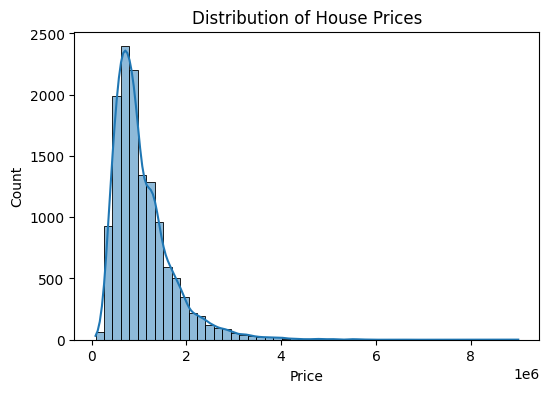

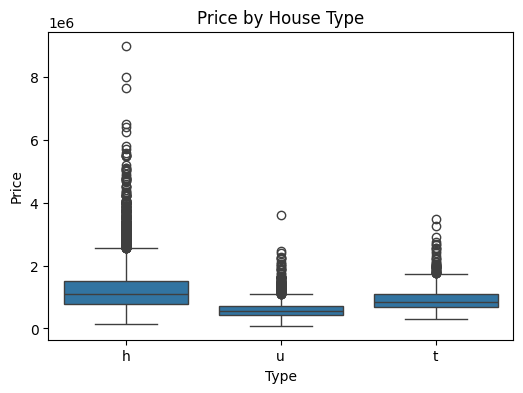

In [5]:
# EDA (short demo plots)
plt.figure(figsize=(6,4))
sns.histplot(data['Price'], bins=50, kde=True)
plt.title("Distribution of House Prices")
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(x="Type", y="Price", data=data)
plt.title("Price by House Type")
plt.show()

In [6]:
# Preprocessing
# - Numerical: impute missing values with median
# - Categorical: impute missing with most frequent + one-hot encode
numeric_transformer = SimpleImputer(strategy="median")
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ])


In [7]:
# Split data
train_X, val_X, train_y, val_y = train_test_split(X, y, random_state=1)

print("\nData split into training and validation sets")
print(f"Training set size: {len(train_X)} rows")
print(f"Validation set size: {len(val_X)} rows")


Data split into training and validation sets
Training set size: 10185 rows
Validation set size: 3395 rows


In [8]:
# Decision Tree
dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(max_depth=10, random_state=1))
])
dt_model.fit(train_X, train_y)

# Random Forest with hyperparameter tuning
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=1))
])

# Small hyperparameter grid for quick tuning
param_grid = {
    "model__n_estimators": [50, 100],
    "model__max_depth": [10, 20, None]
}

grid_search = GridSearchCV(rf_pipeline, param_grid, cv=3, scoring="neg_mean_absolute_error", n_jobs=-1)
grid_search.fit(train_X, train_y)

best_rf_model = grid_search.best_estimator_

print("\nDecision Tree model trained.")
print("Random Forest model trained with GridSearchCV.")
print("Best Random Forest parameters:", grid_search.best_params_)


Decision Tree model trained.
Random Forest model trained with GridSearchCV.
Best Random Forest parameters: {'model__max_depth': None, 'model__n_estimators': 100}


In [9]:
# Evaluate
dt_val_predictions = dt_model.predict(val_X)
dt_mae = mean_absolute_error(val_y, dt_val_predictions)

rf_val_predictions = best_rf_model.predict(val_X)
rf_mae = mean_absolute_error(val_y, rf_val_predictions)

print(f"\nDecision Tree MAE: ${dt_mae:,.2f}")
print(f"Random Forest MAE: ${rf_mae:,.2f}")



Decision Tree MAE: $213,755.70
Random Forest MAE: $163,581.27


In [10]:
# Example prediction
new_house_data = pd.DataFrame([[2, 1, 150, 80, 1990, -37.8, 145.0, "h", "Northern Metropolitan"]],
                              columns=numerical_features + categorical_features)

dt_pred_price = dt_model.predict(new_house_data)[0]
rf_pred_price = best_rf_model.predict(new_house_data)[0]

print("\n--- Example Prediction ---")
print(f"House features: {new_house_data.iloc[0].to_dict()}")
print(f"Decision Tree Predicted Price: ${dt_pred_price:,.2f}")
print(f"Random Forest Predicted Price: ${rf_pred_price:,.2f}")


--- Example Prediction ---
House features: {'Rooms': 2, 'Bathroom': 1, 'Landsize': 150, 'BuildingArea': 80, 'YearBuilt': 1990, 'Lattitude': -37.8, 'Longtitude': 145.0, 'Type': 'h', 'Regionname': 'Northern Metropolitan'}
Decision Tree Predicted Price: $1,030,150.15
Random Forest Predicted Price: $982,680.00
